<a href="https://colab.research.google.com/github/Nkajabi/cs50.readthedocs.io/blob/main/NEW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ============================================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# ============================================================

%pip install -q -U datasets huggingface_hub
%pip install -q -U scikit-learn scikit-image
%pip install -q -U xgboost shap
%pip install -q -U opencv-python-headless imagehash
%pip install -q -U seaborn matplotlib pandas numpy tqdm Pillow


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:

# ============================================================
# CELL 2: IMPORT ALL LIBRARIES
# ============================================================

import os
import gc
import time
import copy
import random
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

# Hugging Face
from datasets import load_dataset

# Image processing
import cv2
import imagehash
from skimage.feature import hog

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# XGBoost
import xgboost as xgb
from xgboost import XGBClassifier

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import ResNet50_Weights

# Explainable AI
import shap

# Utilities
from collections import defaultdict

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

print("\nLibrary versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)
print("XGBoost:", xgb.__version__)
print("PyTorch:", torch.__version__)
print("SHAP:", shap.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running without GPU. ResNet training will be slower.")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


All libraries imported successfully.

Library versions:
NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1
XGBoost: 3.4.1
PyTorch: 2.14.1+cu130
SHAP: 0.54.1

CUDA available: True
GPU: Tesla T4


In [3]:

# ============================================================
# CELL 3: PROJECT CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Dataset settings
DATASET_NAME = "imadhavan/FER2025"

CLASS_NAMES = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

NUM_CLASSES = len(CLASS_NAMES)

# Initial balanced sample
IMAGES_PER_CLASS = 500
TOTAL_IMAGES = IMAGES_PER_CLASS * NUM_CLASSES

# Image settings
HOG_SIZE = (96, 96)
CNN_SIZE = (224, 224)

# Data splitting
TEST_SIZE = 0.10
VALIDATION_SIZE = 0.10

# Training settings
BATCH_SIZE = 32
EPOCHS = 8
WARMUP_EPOCHS = 2

# Output folder
OUTPUT_DIR = "/content/emotion_recognition_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project configuration loaded.")
print("Device:", DEVICE)
print("Number of classes:", NUM_CLASSES)
print("Target images:", TOTAL_IMAGES)
print("Output folder:", OUTPUT_DIR)


Project configuration loaded.
Device: cuda
Number of classes: 7
Target images: 3500
Output folder: /content/emotion_recognition_results


In [4]:

# ============================================================
# CELL 4: LOAD FER2025
# ============================================================

print("Loading FER2025 dataset...")

dataset_stream = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("Dataset stream created successfully.")

# Inspect one sample
sample_iterator = iter(dataset_stream)
first_sample = next(sample_iterator)

print("\nAvailable dataset fields:")
print(first_sample.keys())

print("\nSample label:")
print(first_sample.get("cls"))

print("\nSample key:")
print(first_sample.get("__key__"))

print("\nImage information:")
image_field = first_sample.get("image")

if image_field is None:
    image_field = first_sample.get("jpg")

if image_field is not None:
    print("Image type:", type(image_field))
    print("Image size:", image_field.size)
else:
    print("Image field not found. Check the printed dataset fields.")


Loading FER2025 dataset...


README.md:   0%|          | 0.00/2.63k [00:00<?, ?B/s]

Dataset stream created successfully.

Available dataset fields:
dict_keys(['jpg', 'cls', '__key__', '__url__'])

Sample label:
0

Sample key:
Angry_000000

Image information:
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (75, 75)


In [5]:

# ============================================================
# CELL 5: COLLECT BALANCED DATASET
# ============================================================

images = []
labels = []
image_keys = []

class_counts = {
    i: 0 for i in range(NUM_CLASSES)
}

seen_hashes = set()

print("Collecting images from FER2025...")

dataset_stream = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

for row in tqdm(dataset_stream):

    # Stop when all classes reach their target
    if all(
        class_counts[i] >= IMAGES_PER_CLASS
        for i in range(NUM_CLASSES)
    ):
        break

    try:
        # Read image
        image = row.get("image")

        if image is None:
            image = row.get("jpg")

        if image is None:
            continue

        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.array(image))

        image = image.convert("RGB")

        # Read numeric label
        label = int(row["cls"])

        if label < 0 or label >= NUM_CLASSES:
            continue

        if class_counts[label] >= IMAGES_PER_CLASS:
            continue

        # Resize to reduce memory usage
        image = image.resize(
            (112, 112),
            Image.Resampling.LANCZOS
        )

        # Remove exact perceptual-hash duplicates
        phash_value = str(imagehash.phash(image))

        if phash_value in seen_hashes:
            continue

        image_array = np.array(image, dtype=np.uint8)

        if image_array.shape != (112, 112, 3):
            continue

        if not np.isfinite(image_array).all():
            continue

        images.append(image_array)
        labels.append(label)
        image_keys.append(row.get("__key__", ""))

        seen_hashes.add(phash_value)
        class_counts[label] += 1

    except Exception as error:
        continue

print("\nDataset collection completed.")

print("Total collected images:", len(images))

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        class_name,
        ":",
        class_counts[class_id]
    )

if len(images) == 0:
    raise RuntimeError(
        "No images were collected. Check the dataset fields from Cell 4."
    )

if min(class_counts.values()) < IMAGES_PER_CLASS:
    print(
        "\nWARNING: Some classes did not reach the target. "
        "The actual collected counts will be used."
    )

X_images = np.asarray(images, dtype=np.uint8)
y = np.asarray(labels, dtype=np.int64)

del images, labels
gc.collect()

print("\nFinal image array:", X_images.shape)
print("Final label array:", y.shape)


0it [00:00, ?it/s]


Dataset collection completed.
Total collected images: 3500
Angry : 500
Disgust : 500
Fear : 500
Happy : 500
Neutral : 500
Sad : 500
Surprise : 500

Final image array: (3500, 112, 112, 3)
Final label array: (3500,)


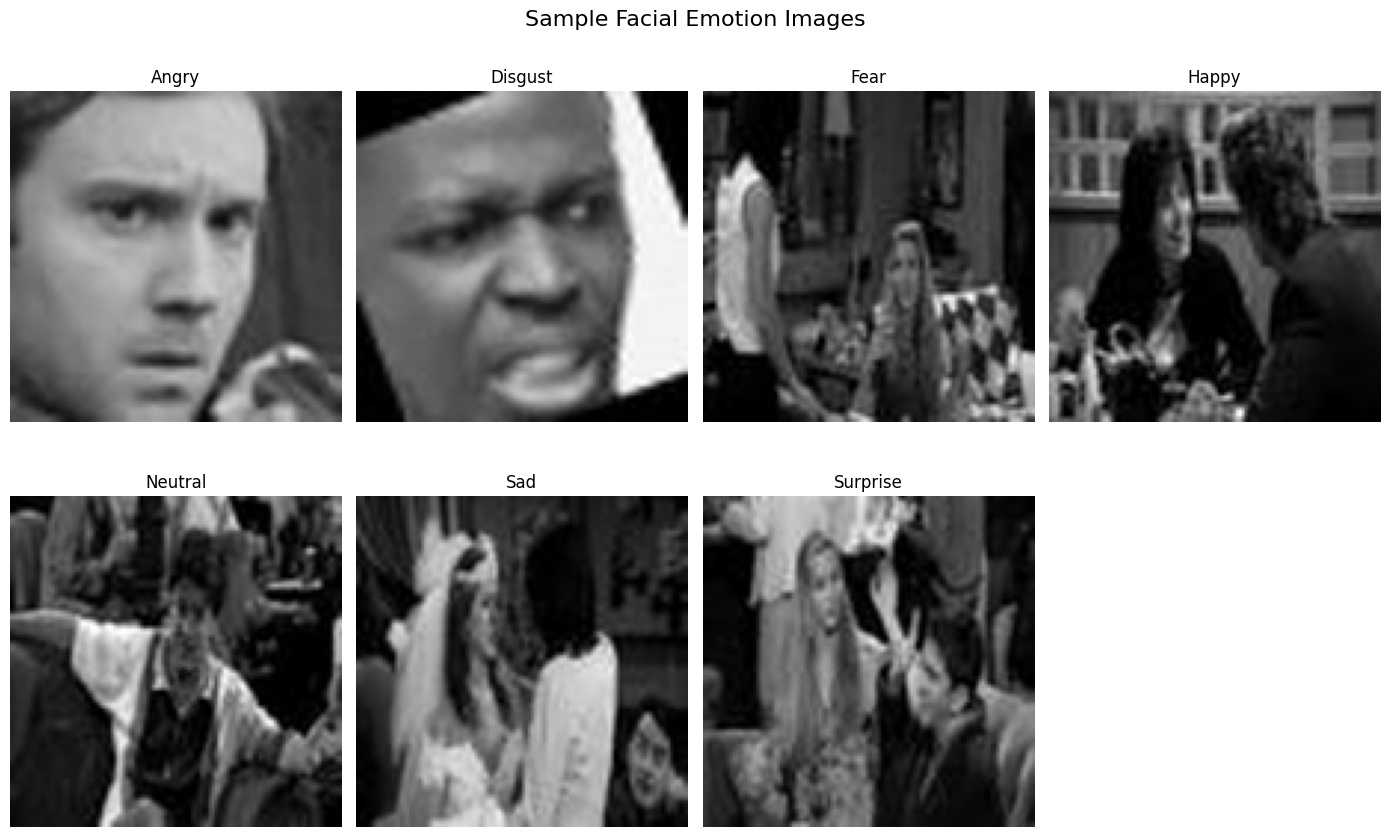

In [6]:

# ============================================================
# CELL 6: VISUALIZE SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(14, 9))

for class_id, class_name in enumerate(CLASS_NAMES):

    indices = np.where(y == class_id)[0]

    if len(indices) == 0:
        continue

    selected_index = indices[0]

    plt.subplot(2, 4, class_id + 1)

    plt.imshow(X_images[selected_index])
    plt.title(class_name)
    plt.axis("off")

plt.suptitle(
    "Sample Facial Emotion Images",
    fontsize=16
)

plt.tight_layout()
plt.show()


,Emotion,Image Count
0,Angry,500
1,Disgust,500
2,Fear,500
3,Happy,500
4,Neutral,500
5,Sad,500
6,Surprise,500


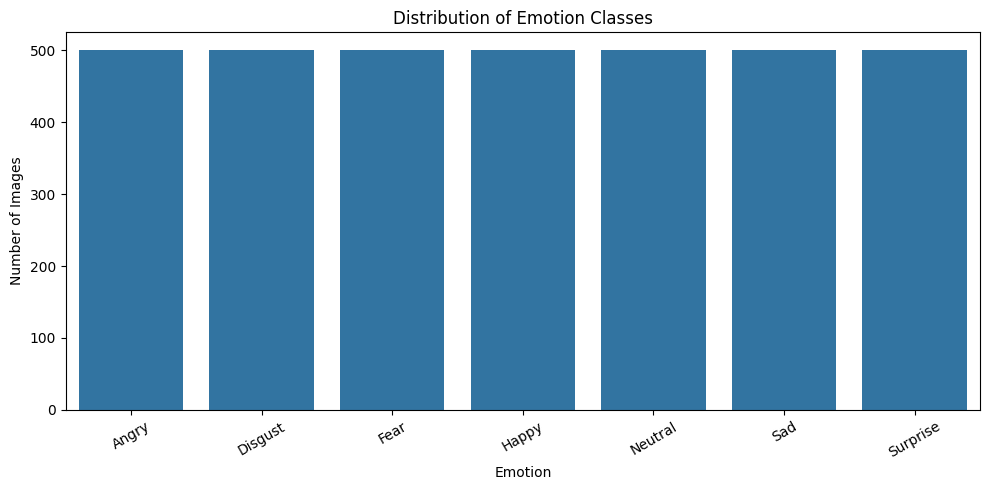

In [7]:

# ============================================================
# CELL 7: CLASS DISTRIBUTION
# ============================================================

class_distribution = pd.Series(y).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Emotion": CLASS_NAMES,
    "Image Count": [
        int(class_distribution.get(i, 0))
        for i in range(NUM_CLASSES)
    ]
})

display(distribution_df)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution_df,
    x="Emotion",
    y="Image Count"
)

plt.title("Distribution of Emotion Classes")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [8]:

# ============================================================
# CELL 8: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

indices = np.arange(len(y))

train_indices, temporary_indices = train_test_split(
    indices,
    test_size=TEST_SIZE + VALIDATION_SIZE,
    random_state=SEED,
    stratify=y
)

temporary_labels = y[temporary_indices]

validation_fraction_of_temporary = (
    VALIDATION_SIZE /
    (TEST_SIZE + VALIDATION_SIZE)
)

validation_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=1 - validation_fraction_of_temporary,
    random_state=SEED,
    stratify=temporary_labels
)

X_train_images = X_images[train_indices]
X_val_images = X_images[validation_indices]
X_test_images = X_images[test_indices]

y_train = y[train_indices]
y_val = y[validation_indices]
y_test = y[test_indices]

print("Training images:", len(y_train))
print("Validation images:", len(y_val))
print("Testing images:", len(y_test))

print("\nTraining proportions:")
print(pd.Series(y_train).value_counts().sort_index())


Training images: 2800
Validation images: 350
Testing images: 350

Training proportions:
0    400
1    400
2    400
3    400
4    400
5    400
6    400
Name: count, dtype: int64


In [9]:

# ============================================================
# CELL 9: HOG FEATURE EXTRACTION
# ============================================================

def extract_hog_features(image_array):

    gray = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2GRAY
    )

    gray = cv2.resize(
        gray,
        HOG_SIZE
    )

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )

    return features.astype(np.float32)


def create_hog_dataset(image_array, description):

    feature_list = []

    for image in tqdm(
        image_array,
        desc=description
    ):
        feature_list.append(
            extract_hog_features(image)
        )

    return np.asarray(
        feature_list,
        dtype=np.float32
    )


X_train_hog = create_hog_dataset(
    X_train_images,
    "Extracting training HOG features"
)

X_val_hog = create_hog_dataset(
    X_val_images,
    "Extracting validation HOG features"
)

X_test_hog = create_hog_dataset(
    X_test_images,
    "Extracting testing HOG features"
)

print("Training HOG:", X_train_hog.shape)
print("Validation HOG:", X_val_hog.shape)
print("Testing HOG:", X_test_hog.shape)


Extracting training HOG features:   0%|          | 0/2800 [00:00<?, ?it/s]

Extracting validation HOG features:   0%|          | 0/350 [00:00<?, ?it/s]

Extracting testing HOG features:   0%|          | 0/350 [00:00<?, ?it/s]

Training HOG: (2800, 4356)
Validation HOG: (350, 4356)
Testing HOG: (350, 4356)


In [10]:

# ============================================================
# CELL 10: FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_hog
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val_hog
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test_hog
).astype(np.float32)

print("HOG features scaled successfully.")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


HOG features scaled successfully.
Training: (2800, 4356)
Validation: (350, 4356)
Testing: (350, 4356)


In [11]:

# ============================================================
# CELL 11: RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=250,
    max_depth=30,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

print("Training Random Forest...")

rf_start = time.time()

rf_model.fit(
    X_train_scaled,
    y_train
)

rf_training_time = time.time() - rf_start

print("Random Forest training completed.")
print("Training time:", round(rf_training_time, 2), "seconds")


Training Random Forest...
Random Forest training completed.
Training time: 31.21 seconds


In [12]:

# ============================================================
# CELL 12: RANDOM FOREST PREDICTIONS
# ============================================================

rf_start = time.time()

rf_predictions = rf_model.predict(
    X_test_scaled
)

rf_probabilities = rf_model.predict_proba(
    X_test_scaled
)

rf_inference_time = (
    time.time() - rf_start
) / len(y_test)

print("Random Forest predictions completed.")
print("Prediction count:", len(rf_predictions))


Random Forest predictions completed.
Prediction count: 350


In [13]:

# ============================================================
# CELL 13: XGBOOST CONFIGURATION
# ============================================================

# Use GPU only when PyTorch confirms CUDA is available.
# If XGBoost itself cannot use the GPU, Cell 14 retries on CPU.

XGB_DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("XGBoost version:", xgb.__version__)
print("Selected XGBoost device:", XGB_DEVICE)


XGBoost version: 3.4.1
Selected XGBoost device: cuda


In [14]:

# ============================================================
# CELL 14: TRAIN XGBOOST
# ============================================================

def create_xgb_model(device):

    return XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.08,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=2,
        reg_lambda=2,
        objective="multi:softprob",
        num_class=NUM_CLASSES,
        eval_metric="mlogloss",
        tree_method="hist",
        device=device,
        n_jobs=4,
        random_state=SEED
    )


xgb_model = create_xgb_model(XGB_DEVICE)

print("Training XGBoost...")

xgb_start = time.time()

try:
    xgb_model.fit(
        X_train_scaled,
        y_train,
        eval_set=[(X_val_scaled, y_val)],
        verbose=False
    )

except Exception as error:

    if XGB_DEVICE == "cuda":

        print("\nGPU training failed.")
        print("Reason:", str(error)[:500])
        print("Retrying XGBoost on CPU...")

        XGB_DEVICE = "cpu"
        xgb_model = create_xgb_model("cpu")

        xgb_model.fit(
            X_train_scaled,
            y_train,
            eval_set=[(X_val_scaled, y_val)],
            verbose=False
        )

    else:
        raise

xgb_training_time = time.time() - xgb_start

print("\nXGBoost training completed.")
print("Device used:", XGB_DEVICE)
print("Training time:", round(xgb_training_time, 2), "seconds")


Training XGBoost...

XGBoost training completed.
Device used: cuda
Training time: 44.67 seconds


In [15]:

# ============================================================
# CELL 15: XGBOOST PREDICTIONS
# ============================================================

xgb_start = time.time()

xgb_predictions = xgb_model.predict(
    X_test_scaled
)

xgb_probabilities = xgb_model.predict_proba(
    X_test_scaled
)

xgb_inference_time = (
    time.time() - xgb_start
) / len(y_test)

print("XGBoost predictions completed.")


XGBoost predictions completed.


In [16]:

# ============================================================
# CELL 16: RESNET IMAGE TRANSFORMATIONS
# ============================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((240, 240)),
    transforms.RandomResizedCrop(
        224,
        scale=(0.90, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(12),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.08
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

evaluation_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

print("Image transformations created.")


Image transformations created.


In [17]:

# ============================================================
# CELL 17: PYTORCH DATASET
# ============================================================

class EmotionDataset(Dataset):

    def __init__(self, images, labels, transform=None):

        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        image = Image.fromarray(
            self.images[index]
        ).convert("RGB")

        label = int(self.labels[index])

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = EmotionDataset(
    X_train_images,
    y_train,
    train_transform
)

val_dataset = EmotionDataset(
    X_val_images,
    y_val,
    evaluation_transform
)

test_dataset = EmotionDataset(
    X_test_images,
    y_test,
    evaluation_transform
)

NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("DataLoaders created.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created.
Training batches: 88
Validation batches: 11
Testing batches: 11


In [18]:

# ============================================================
# CELL 18: RESNET-50 MODEL
# ============================================================

weights = ResNet50_Weights.DEFAULT

resnet_model = models.resnet50(
    weights=weights
)

# Freeze pretrained layers initially
for parameter in resnet_model.parameters():
    parameter.requires_grad = False

# Replace the final classification layer
input_features = resnet_model.fc.in_features

resnet_model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(
        input_features,
        NUM_CLASSES
    )
)

resnet_model = resnet_model.to(DEVICE)

print("ResNet-50 loaded successfully.")
print("Output classes:", NUM_CLASSES)
print("Device:", DEVICE)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


ResNet-50 loaded successfully.
Output classes: 7
Device: cuda


In [19]:

# ============================================================
# CELL 19: TRAINING CONFIGURATION
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# First stage: train only the classification head
optimizer = optim.AdamW(
    resnet_model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = None

scaler_amp = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(
    resnet_model.state_dict()
)

patience = 3
epochs_without_improvement = 0

print("Training configuration ready.")


Training configuration ready.


In [20]:

# ============================================================
# CELL 19: TRAINING CONFIGURATION
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# First stage: train only the classification head
optimizer = optim.AdamW(
    resnet_model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = None

scaler_amp = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(
    resnet_model.state_dict()
)

patience = 3
epochs_without_improvement = 0

print("Training configuration ready.")


Training configuration ready.


In [21]:

# ============================================================
# CELL 20: TRAINING AND VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in tqdm(
        loader,
        leave=False
    ):

        batch_images = batch_images.to(
            DEVICE,
            non_blocking=True
        )

        batch_labels = batch_labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

        scaler_amp.scale(loss).backward()
        scaler_amp.step(optimizer)
        scaler_amp.update()

        total_loss += loss.item() * batch_labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    return (
        total_loss / total,
        correct / total
    )


def validate_one_epoch(model, loader):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch_images, batch_labels in loader:

            batch_images = batch_images.to(
                DEVICE,
                non_blocking=True
            )

            batch_labels = batch_labels.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = model(batch_images)
                loss = criterion(outputs, batch_labels)

            total_loss += loss.item() * batch_labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == batch_labels
            ).sum().item()

            total += batch_labels.size(0)

    return (
        total_loss / total,
        correct / total
    )


print("Training functions defined.")


Training functions defined.


In [22]:

# ============================================================
# CELL 21: TRAIN RESNET-50
# ============================================================

resnet_start = time.time()

for epoch in range(EPOCHS):

    # Unfreeze final residual block after warmup
    if epoch == WARMUP_EPOCHS:

        for parameter in resnet_model.layer4.parameters():
            parameter.requires_grad = True

        optimizer = optim.AdamW(
            [
                {
                    "params": resnet_model.layer4.parameters(),
                    "lr": 0.0001
                },
                {
                    "params": resnet_model.fc.parameters(),
                    "lr": 0.0003
                }
            ],
            weight_decay=0.0001
        )

        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=max(1, EPOCHS - WARMUP_EPOCHS)
        )

        print("\nFinal ResNet block unfrozen.")

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_accuracy = train_one_epoch(
        resnet_model,
        train_loader,
        optimizer
    )

    val_loss, val_accuracy = validate_one_epoch(
        resnet_model,
        val_loader
    )

    if scheduler is not None:
        scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            resnet_model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping activated.")
        break


resnet_model.load_state_dict(best_model_weights)

resnet_training_time = time.time() - resnet_start

print("\nResNet training completed.")
print(
    "Training time:",
    round(resnet_training_time, 2),
    "seconds"
)



Epoch 1/8


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss: 1.9495 | Train Accuracy: 0.1654
Validation Loss: 1.9154 | Validation Accuracy: 0.1857

Epoch 2/8


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss: 1.9019 | Train Accuracy: 0.2211
Validation Loss: 1.8723 | Validation Accuracy: 0.2486

Final ResNet block unfrozen.

Epoch 3/8


  0%|          | 0/88 [00:00<?, ?it/s]

... (8 outputs left out)

  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss: 1.5870 | Train Accuracy: 0.4571
Validation Loss: 1.7215 | Validation Accuracy: 0.3543

Epoch 8/8


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss: 1.5533 | Train Accuracy: 0.4586
Validation Loss: 1.7030 | Validation Accuracy: 0.3486

ResNet training completed.
Training time: 219.96 seconds


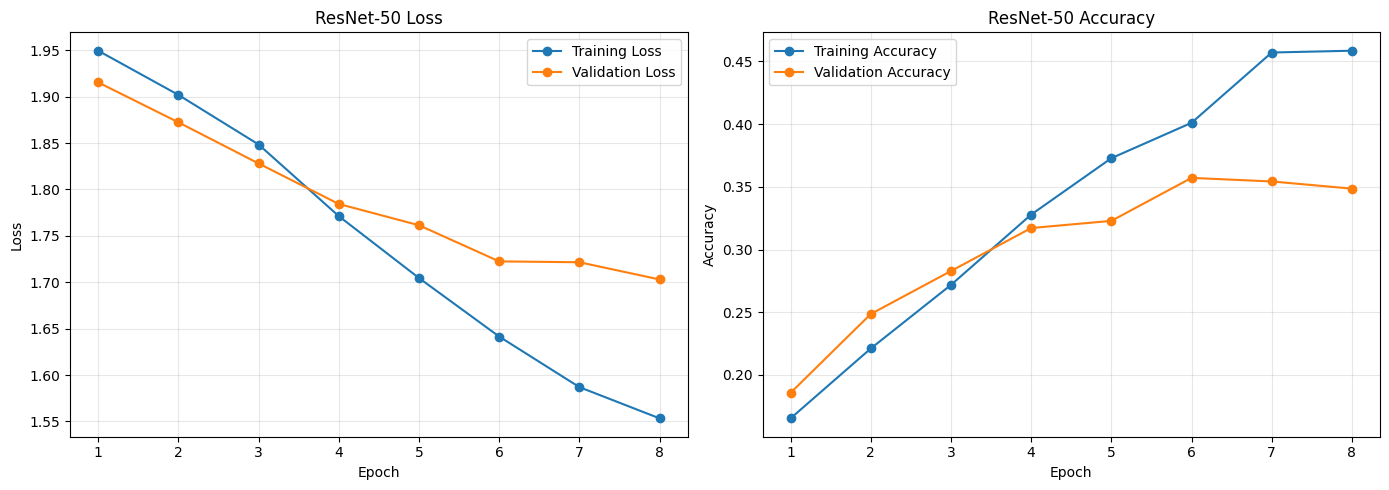

In [23]:

# ============================================================
# CELL 22: RESNET TRAINING CURVES
# ============================================================

epochs_completed = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_completed,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("ResNet-50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)

plt.plot(
    epochs_completed,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("ResNet-50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "resnet_training_curves.png"),
    dpi=300
)

plt.show()


In [24]:

# ============================================================
# CELL 23: RESNET TEST PREDICTIONS
# ============================================================

resnet_model.eval()

resnet_predictions = []
resnet_probabilities = []

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

resnet_inference_start = time.time()

with torch.no_grad():

    for batch_images, batch_labels in tqdm(
        test_loader,
        desc="ResNet testing"
    ):

        batch_images = batch_images.to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = resnet_model(batch_images)

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )

        predictions = probabilities.argmax(dim=1)

        resnet_predictions.extend(
            predictions.cpu().numpy()
        )

        resnet_probabilities.extend(
            probabilities.cpu().numpy()
        )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

resnet_inference_time = (
    time.time() - resnet_inference_start
) / len(y_test)

resnet_predictions = np.asarray(
    resnet_predictions
)

resnet_probabilities = np.asarray(
    resnet_probabilities
)

print("ResNet predictions completed.")


ResNet testing:   0%|          | 0/11 [00:00<?, ?it/s]

ResNet predictions completed.


In [25]:

# ============================================================
# CELL 24: MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities,
    training_time,
    inference_time
):

    results = {
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "Macro Precision": precision_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted Precision": precision_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted Recall": recall_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Training Time (s)": training_time,

        "Inference Time (ms/image)": inference_time * 1000
    }

    try:

        results["Weighted ROC-AUC"] = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="weighted"
        )

    except ValueError:

        results["Weighted ROC-AUC"] = np.nan

    return results


In [26]:

# ============================================================
# CELL 25: COMPARE ALL MODELS
# ============================================================

results = []

results.append(
    evaluate_model(
        "Random Forest + HOG",
        y_test,
        rf_predictions,
        rf_probabilities,
        rf_training_time,
        rf_inference_time
    )
)

results.append(
    evaluate_model(
        "XGBoost + HOG",
        y_test,
        xgb_predictions,
        xgb_probabilities,
        xgb_training_time,
        xgb_inference_time
    )
)

results.append(
    evaluate_model(
        "ResNet-50",
        y_test,
        resnet_predictions,
        resnet_probabilities,
        resnet_training_time,
        resnet_inference_time
    )
)

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

print("Model comparison saved.")


,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Training Time (s),Inference Time (ms/image),Weighted ROC-AUC
0,Random Forest + HOG,0.5943,0.5932,0.5932,0.5943,0.5943,0.5929,0.5929,31.2143,1.0021,0.8573
1,XGBoost + HOG,0.5971,0.6045,0.6045,0.5971,0.5971,0.5985,0.5985,44.6656,0.3492,0.8733
2,ResNet-50,0.3514,0.3488,0.3488,0.3514,0.3514,0.3421,0.3421,219.9636,3.8589,0.7331


Model comparison saved.


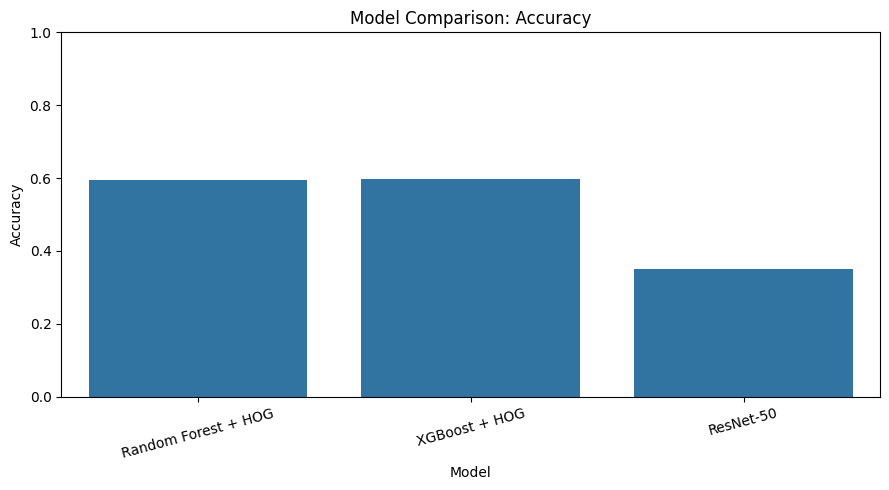

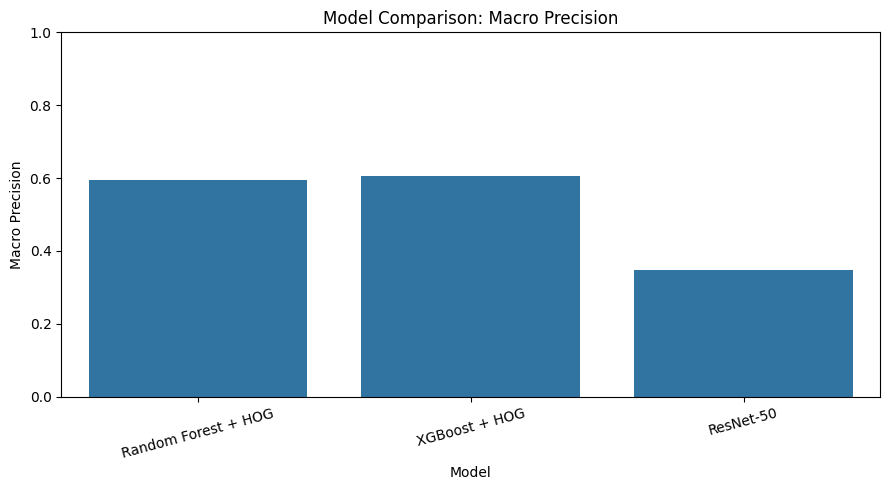

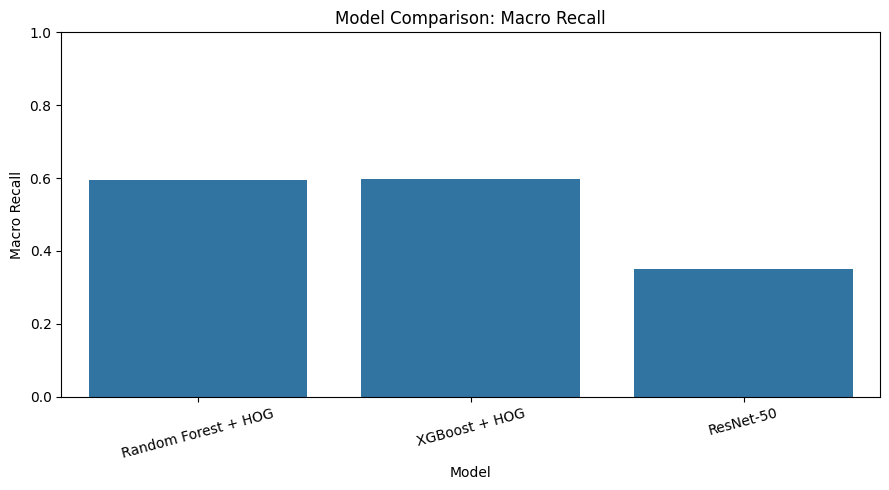

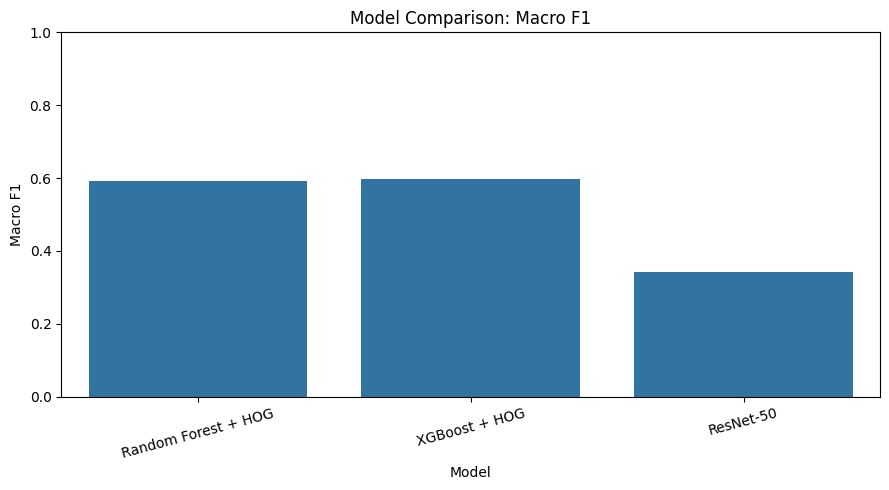

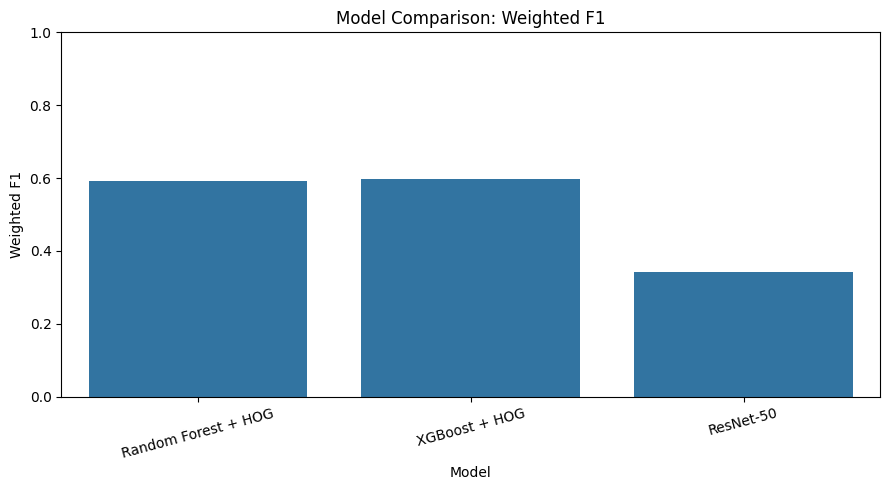

In [27]:

# ============================================================
# CELL 26: PERFORMANCE COMPARISON CHARTS
# ============================================================

comparison_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

for metric in comparison_metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison: {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.xticks(rotation=15)
    plt.ylim(0, 1)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"comparison_{metric.replace(' ', '_')}.png"
        ),
        dpi=300
    )

    plt.show()


In [28]:

# ============================================================
# CELL 27: CLASSIFICATION REPORTS
# ============================================================

all_predictions = {
    "Random Forest + HOG": rf_predictions,
    "XGBoost + HOG": xgb_predictions,
    "ResNet-50": resnet_predictions
}

for model_name, predictions in all_predictions.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            predictions,
            labels=np.arange(NUM_CLASSES),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )



Random Forest + HOG
              precision    recall  f1-score   support

       Angry     0.6275    0.6400    0.6337        50
     Disgust     0.8043    0.7400    0.7708        50
        Fear     0.7273    0.8000    0.7619        50
       Happy     0.4259    0.4600    0.4423        50
     Neutral     0.4186    0.3600    0.3871        50
         Sad     0.6000    0.6000    0.6000        50
    Surprise     0.5490    0.5600    0.5545        50

    accuracy                         0.5943       350
   macro avg     0.5932    0.5943    0.5929       350
weighted avg     0.5932    0.5943    0.5929       350


XGBoost + HOG
              precision    recall  f1-score   support

       Angry     0.7381    0.6200    0.6739        50
     Disgust     0.8039    0.8200    0.8119        50
        Fear     0.7368    0.8400    0.7850        50
       Happy     0.4000    0.4400    0.4190        50
     Neutral     0.3684    0.4200    0.3925        50
         Sad     0.6190    0.5200    0.565

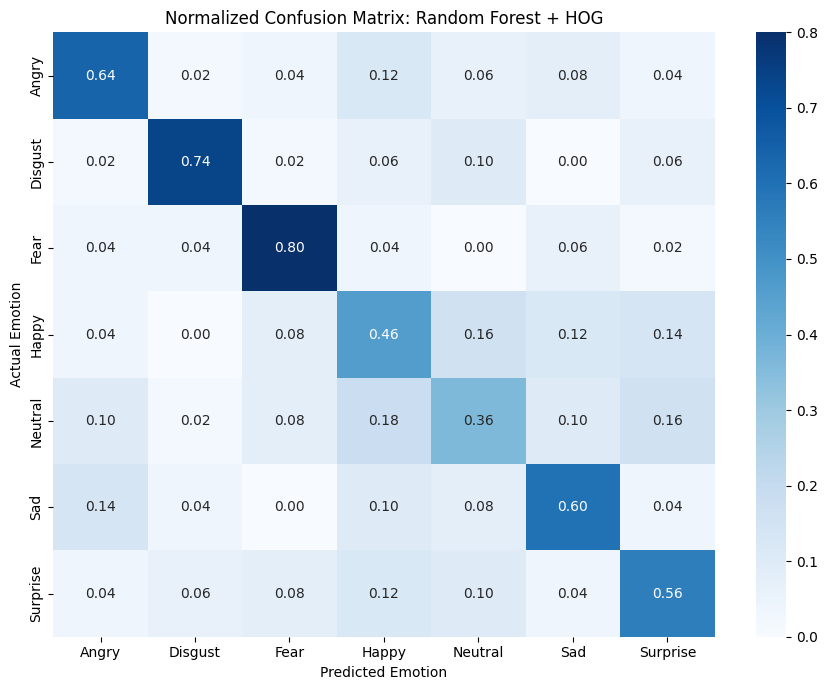

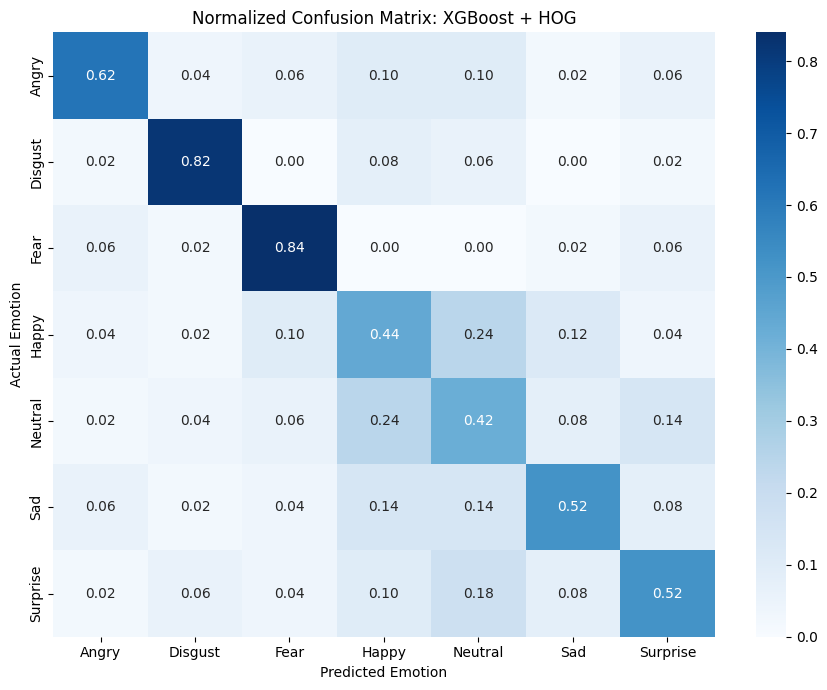

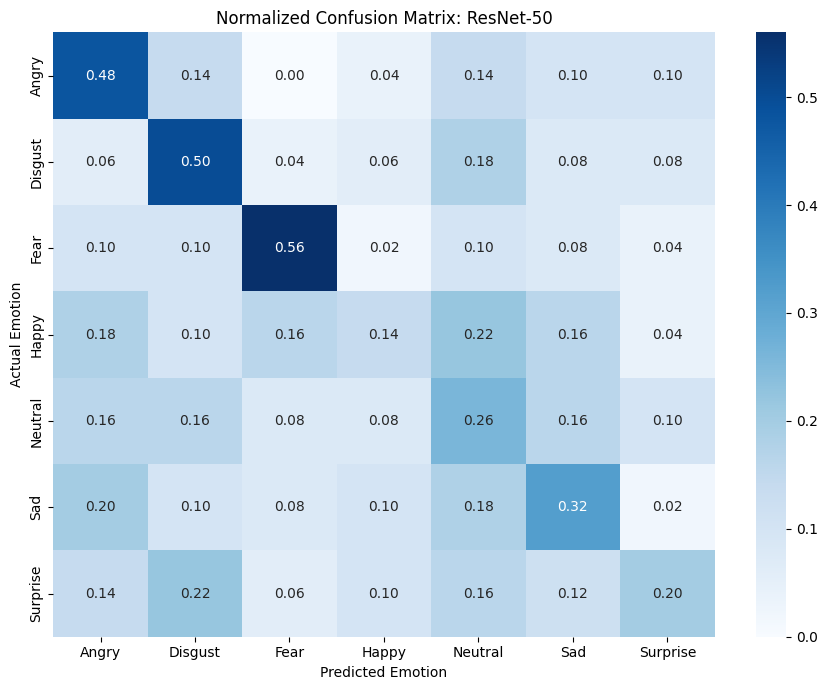

In [29]:

# ============================================================
# CELL 28: CONFUSION MATRICES
# ============================================================

for model_name, predictions in all_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
        normalize="true"
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(
        f"Normalized Confusion Matrix: {model_name}"
    )

    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")

    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("+", "and")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"confusion_matrix_{filename}.png"
        ),
        dpi=300
    )

    plt.show()


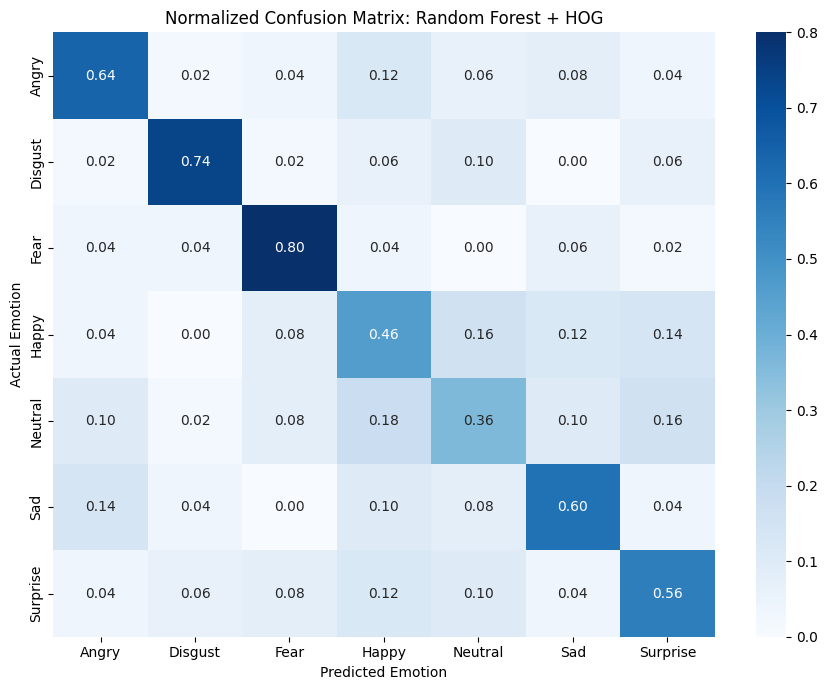

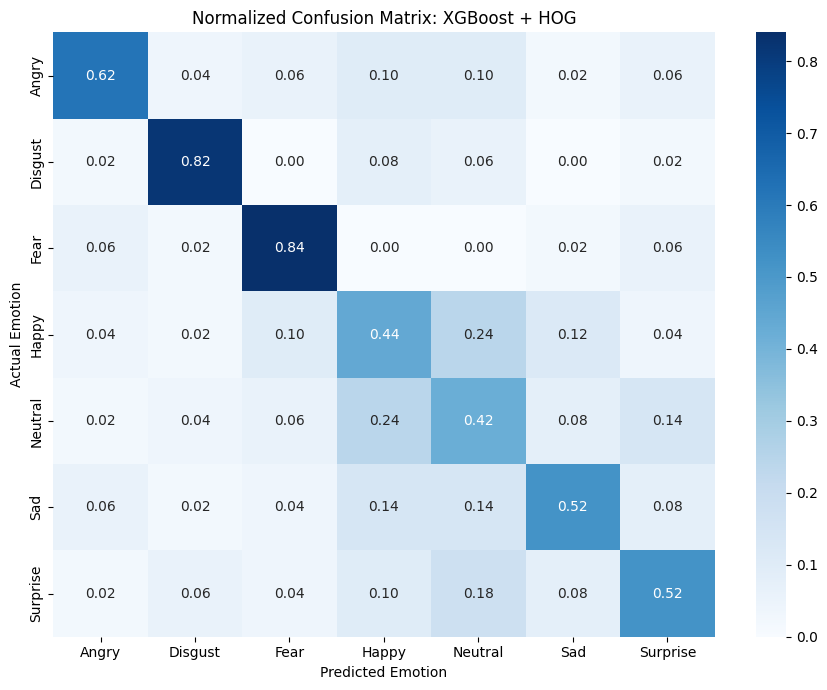

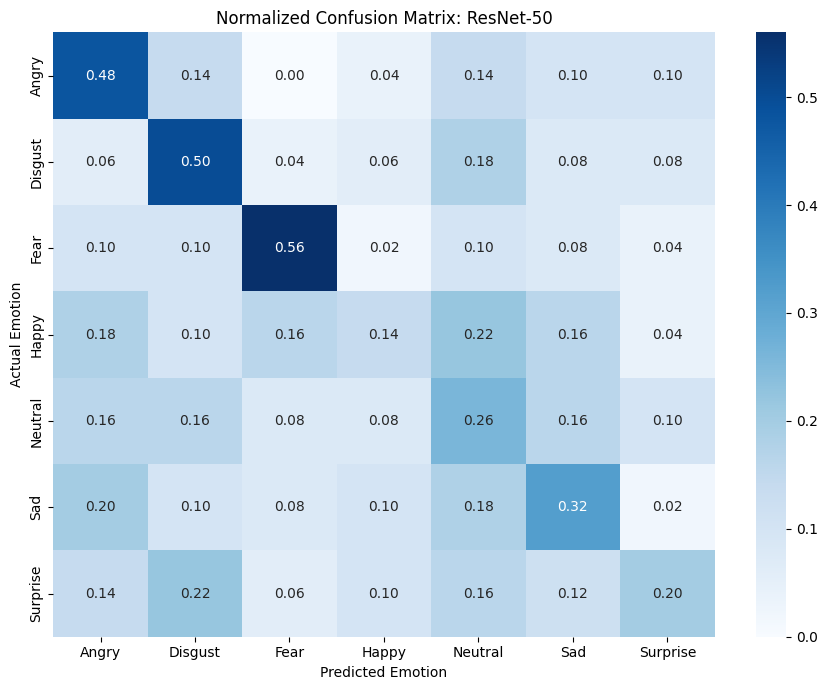

In [30]:

# ============================================================
# CELL 28: CONFUSION MATRICES
# ============================================================

for model_name, predictions in all_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
        normalize="true"
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(
        f"Normalized Confusion Matrix: {model_name}"
    )

    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")

    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("+", "and")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"confusion_matrix_{filename}.png"
        ),
        dpi=300
    )

    plt.show()


In [31]:

# ============================================================
# CELL 29: SHAP FOR XGBOOST
# ============================================================

print("Preparing SHAP explanation...")

SHAP_SAMPLE_SIZE = min(
    100,
    len(X_test_scaled)
)

rng = np.random.default_rng(SEED)

shap_indices = rng.choice(
    len(X_test_scaled),
    size=SHAP_SAMPLE_SIZE,
    replace=False
)

X_shap = X_test_scaled[shap_indices]

shap_explainer = shap.TreeExplainer(
    xgb_model
)

shap_output = shap_explainer(
    X_shap
)

print("SHAP calculation completed.")
print("SHAP output shape:", shap_output.values.shape)


Preparing SHAP explanation...
SHAP calculation completed.
SHAP output shape: (100, 4356, 7)



SHAP explanation: Angry


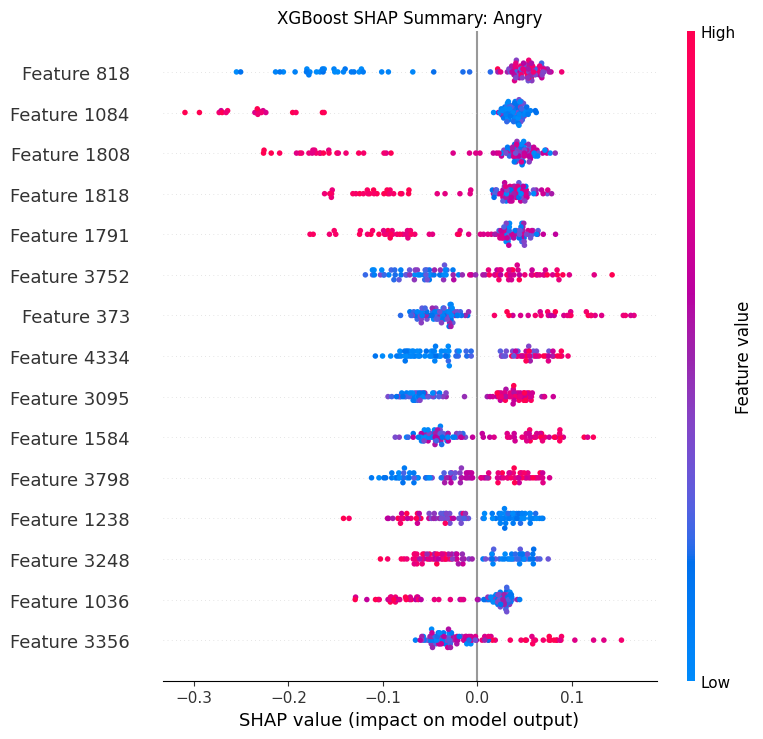


SHAP explanation: Disgust


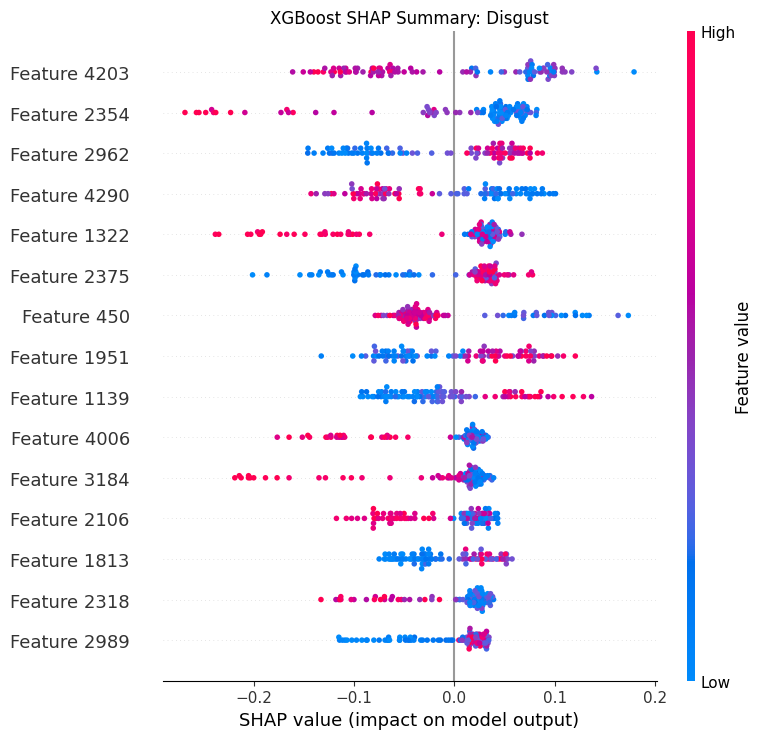


SHAP explanation: Fear


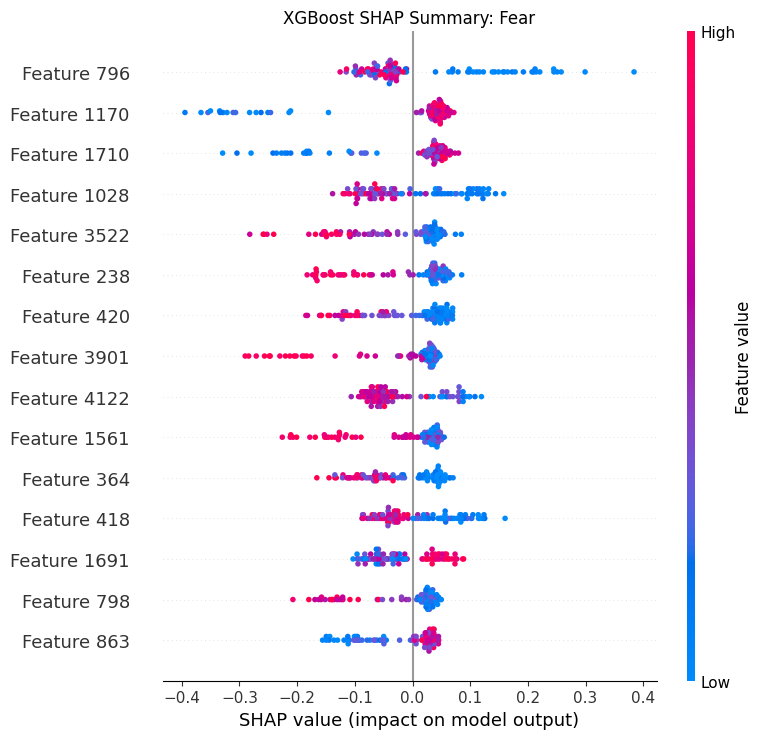


SHAP explanation: Happy


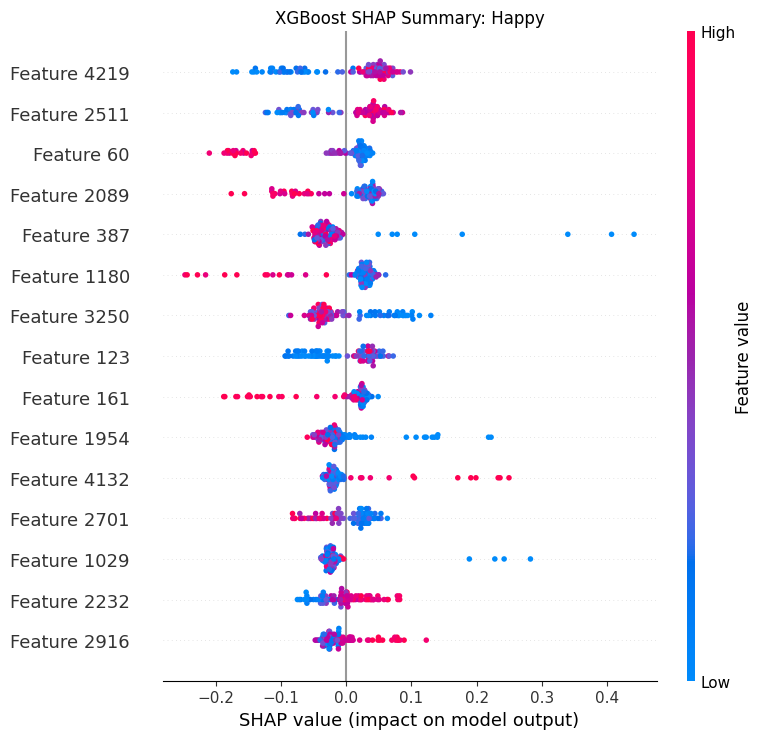


SHAP explanation: Neutral


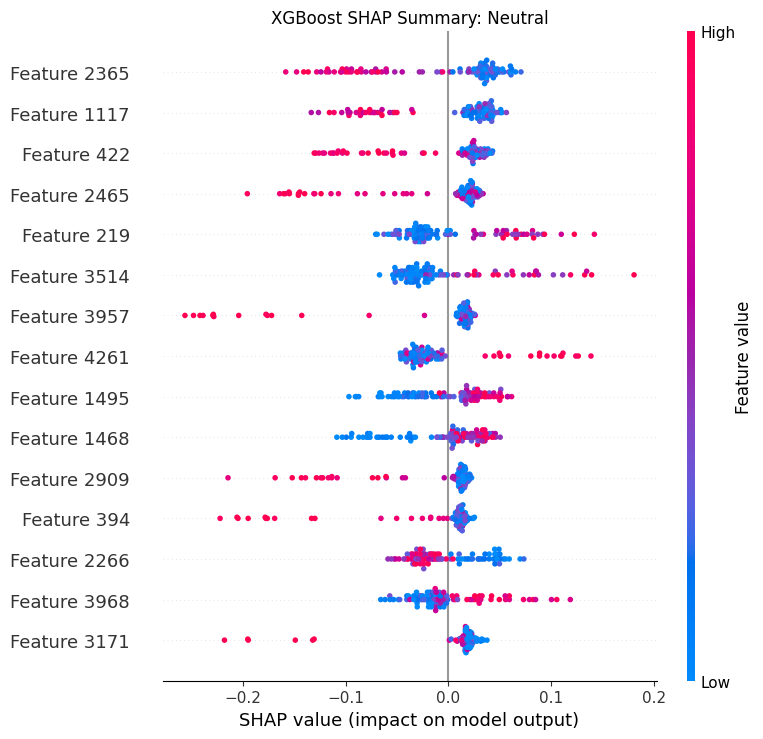


SHAP explanation: Sad


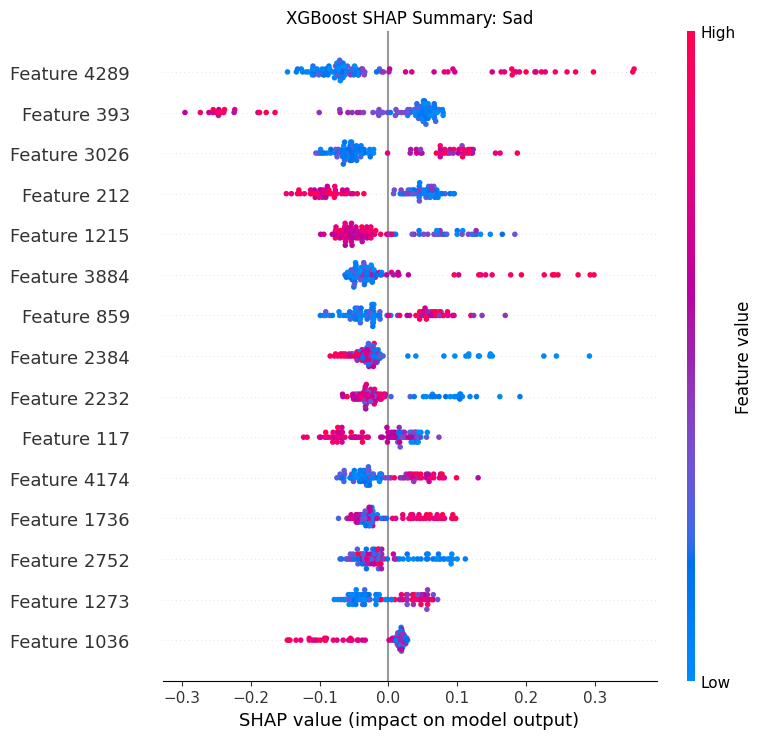


SHAP explanation: Surprise


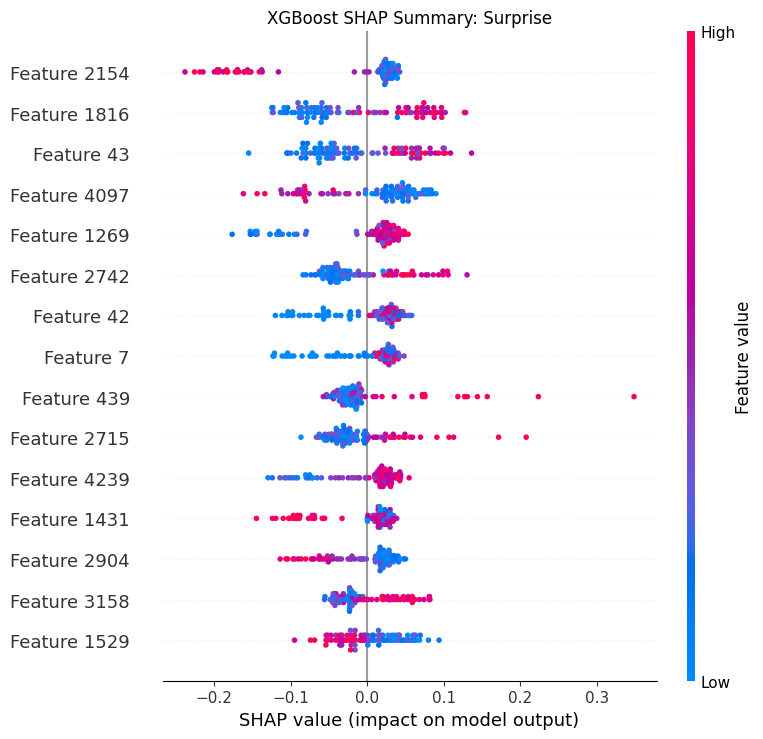

In [32]:

# ============================================================
# CELL 30: SHAP SUMMARY PLOTS
# ============================================================

shap_values_array = np.asarray(
    shap_output.values
)

# Multi-class SHAP output is usually:
# samples x features x classes

if shap_values_array.ndim == 3:

    for class_id, class_name in enumerate(CLASS_NAMES):

        print("\nSHAP explanation:", class_name)

        shap.summary_plot(
            shap_values_array[:, :, class_id],
            X_shap,
            show=False,
            max_display=15
        )

        plt.title(
            f"XGBoost SHAP Summary: {class_name}"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                f"shap_{class_name.lower()}.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

elif shap_values_array.ndim == 2:

    shap.summary_plot(
        shap_values_array,
        X_shap,
        show=False,
        max_display=15
    )

    plt.title("XGBoost SHAP Summary")
    plt.tight_layout()
    plt.show()

else:

    print(
        "Unexpected SHAP output format:",
        shap_values_array.shape
    )


In [33]:

# ============================================================
# CELL 31: GRAD-CAM IMPLEMENTATION
# ============================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            self.target_layer.register_forward_hook(
                self.save_activation
            )
        )

    def save_activation(self, module, inputs, output):

        self.activations = output

        output.register_hook(
            self.save_gradient
        )

    def save_gradient(self, gradient):

        self.gradients = gradient

    def generate(self, input_tensor, class_index=None):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if class_index is None:
            class_index = output.argmax(dim=1).item()

        score = output[:, class_index].sum()

        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activations
        ).sum(dim=1, keepdim=True)

        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze().detach().cpu().numpy()

        cam = cam - cam.min()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam, class_index

    def close(self):
        self.forward_handle.remove()


gradcam = GradCAM(
    resnet_model,
    resnet_model.layer4[-1]
)

print("Grad-CAM initialized.")


Grad-CAM initialized.
